<a href="https://colab.research.google.com/github/jokoyulistiono81-svg/peta-barito-kuala/blob/main/tutupan_lahan_barito_kuala_landsat9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analisis Tutupan Lahan Kab. Barito Kuala (2021–2026) — Landsat 9 + Google Earth Engine

**Alur:** batas kabupaten → komposit median tahunan Landsat 9 (masking awan) → training Random Forest → klasifikasi per tahun → statistik luas → matriks perubahan → peta & ekspor.

**Catatan penting sebelum menjalankan:**
- Landsat 9 baru diluncurkan September 2021, jadi data **2021 hanya mencakup ±Nov–Des** (komposit lemah). Tahun penuh pertama adalah **2022**, sehingga analisis perubahan memakai 2022 sebagai tahun dasar.
- Data **2026** belum satu tahun penuh (sampai data terbaru yang tersedia di GEE).
- Barito Kuala sangat berawan, sehingga sebagian piksel bisa kosong di komposit (tidak terklasifikasi).
- Label training di sini berasal dari **ESA WorldCover 2021** (pseudo-label), sehingga "akurasi" yang dihitung hanyalah kesesuaian dengan WorldCover, **bukan akurasi sebenarnya**. Untuk hasil yang defensible, ganti dengan titik sampel lapangan / hasil digitasi sendiri.
- Perlu akun Google Earth Engine dan Project ID Google Cloud.

In [3]:
!pip -q install geemap

import ee, geemap
ee.Authenticate()
ee.Initialize(project='peta-barito-kuala')

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

YEARS = [2021, 2022, 2023, 2024, 2025, 2026]
BASE_YEAR = 2022      # tahun dasar untuk analisis perubahan (tahun penuh pertama Landsat 9)
TRAIN_YEAR = 2022     # tahun komposit yang dipakai untuk melatih classifier
EXPORT = False        # True = ekspor raster ke Google Drive

CLASS_NAMES = {
    1: 'Hutan/pohon', 2: 'Semak belukar', 3: 'Rumput', 4: 'Pertanian/sawah',
    5: 'Lahan terbangun', 6: 'Lahan terbuka', 7: 'Badan air',
    8: 'Lahan basah herba', 9: 'Mangrove',
}
PALETTE = ['1b5e20', '8bc34a', 'cddc39', 'ffeb3b', 'e53935', 'bdbdbd', '1e88e5', '00bcd4', '6a1b9a']

In [5]:
# Batas Kabupaten Barito Kuala (FAO GAUL 2015, level 2)
gaul = ee.FeatureCollection('FAO/GAUL/2015/level2')
aoi_fc = gaul.filter(ee.Filter.And(
    ee.Filter.eq('ADM1_NAME', 'Kalimantan Selatan'),
    ee.Filter.stringContains('ADM2_NAME', 'Barito')
))
print('Wilayah ditemukan:', aoi_fc.aggregate_array('ADM2_NAME').getInfo())

# Jika kosong/salah, unggah shapefile batas sendiri sebagai asset GEE lalu pakai:
# aoi_fc = ee.FeatureCollection('users/NAMA/barito_kuala')

aoi = aoi_fc.geometry()
print('Luas (ha):', round(aoi.area(1).divide(10000).getInfo()))

/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for FAO/GAUL/2015/level2! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by FAO/GAUL/2025/level2

Learn more: https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level2

  warnings.warn(warning, category=DeprecationWarning)


Wilayah ditemukan: ['Baritokuala']
Luas (ha): 229425


In [6]:
BANDS = ['blue', 'green', 'red', 'nir', 'swir1', 'swir2', 'ndvi', 'ndwi', 'mndwi', 'ndbi']

def prep_l9(img):
    # Masking awan, bayangan awan, dan dilated cloud dari QA_PIXEL
    qa = img.select('QA_PIXEL')
    mask = (qa.bitwiseAnd(1 << 1).eq(0)      # dilated cloud
            .And(qa.bitwiseAnd(1 << 3).eq(0))  # cloud
            .And(qa.bitwiseAnd(1 << 4).eq(0))) # cloud shadow
    sr = (img.select(['SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B6', 'SR_B7'])
             .multiply(0.0000275).add(-0.2).clamp(0, 1)
             .rename(['blue', 'green', 'red', 'nir', 'swir1', 'swir2']))
    return sr.updateMask(mask).copyProperties(img, ['system:time_start'])

def composite(year):
    col = (ee.ImageCollection('LANDSAT/LC09/C02/T1_L2')
           .filterBounds(aoi)
           .filterDate(f'{year}-01-01', f'{year + 1}-01-01')
           .map(prep_l9))
    n = col.size().getInfo()
    img = col.median()
    ndvi  = img.normalizedDifference(['nir', 'red']).rename('ndvi')
    ndwi  = img.normalizedDifference(['green', 'nir']).rename('ndwi')
    mndwi = img.normalizedDifference(['green', 'swir1']).rename('mndwi')
    ndbi  = img.normalizedDifference(['swir1', 'nir']).rename('ndbi')
    return img.addBands([ndvi, ndwi, mndwi, ndbi]).clip(aoi), n

comps = {}
for y in YEARS:
    comps[y], n = composite(y)
    print(y, '-> jumlah scene Landsat 9:', n)

2021 -> jumlah scene Landsat 9: 3
2022 -> jumlah scene Landsat 9: 36
2023 -> jumlah scene Landsat 9: 42
2024 -> jumlah scene Landsat 9: 39
2025 -> jumlah scene Landsat 9: 38
2026 -> jumlah scene Landsat 9: 36


In [7]:
# Label training: ESA WorldCover 2021 -> kelas lokal
wc = ee.ImageCollection('ESA/WorldCover/v200').first().clip(aoi)
src = [10, 20, 30, 40, 50, 60, 80, 90, 95]
dst = [1, 2, 3, 4, 5, 6, 7, 8, 9]
ref = wc.remap(src, dst).rename('class').toInt()

train_img = comps[TRAIN_YEAR].select(BANDS).addBands(ref)
samples = train_img.stratifiedSample(
    numPoints=0, classBand='class', region=aoi, scale=30, seed=42,
    classValues=dst, classPoints=[400] * len(dst), tileScale=4
).randomColumn('rnd', 42)

train = samples.filter(ee.Filter.lt('rnd', 0.7))
test  = samples.filter(ee.Filter.gte('rnd', 0.7))
print('Jumlah sampel:', samples.size().getInfo())

# Jika punya titik sampel sendiri (FeatureCollection dengan properti 'class' bernilai 1-9
# dan fiturnya sudah memuat nilai band), ganti 'samples' dengan itu.

Jumlah sampel: 3600


In [8]:
clf = ee.Classifier.smileRandomForest(numberOfTrees=200, seed=42).train(
    features=train, classProperty='class', inputProperties=BANDS)

cm = test.classify(clf).errorMatrix('class', 'classification')
print('Overall accuracy (terhadap label WorldCover):', round(cm.accuracy().getInfo(), 3))
print('Kappa:', round(cm.kappa().getInfo(), 3))

maps = {y: comps[y].select(BANDS).classify(clf).rename('class').toByte() for y in YEARS}

Overall accuracy (terhadap label WorldCover): 0.576
Kappa: 0.523


In [9]:
def area_by_class(img):
    groups = (ee.Image.pixelArea().divide(10000).addBands(img)
              .reduceRegion(reducer=ee.Reducer.sum().group(groupField=1, groupName='class'),
                            geometry=aoi, scale=30, maxPixels=1e13, tileScale=4)
              .get('groups').getInfo())
    return {CLASS_NAMES[int(g['class'])]: g['sum'] for g in groups}

rows = {y: area_by_class(maps[y]) for y in YEARS}
df_ha = pd.DataFrame(rows).T.reindex(columns=list(CLASS_NAMES.values())).fillna(0).round(1)
df_ha.index.name = 'Tahun'
df_pct = df_ha.div(df_ha.sum(axis=1), axis=0).mul(100).round(2)

print('Luas (ha) — piksel berawan/kosong tidak ikut terhitung')
display(df_ha)
print('Persentase (%) dari area terklasifikasi')
display(df_pct)

df_ha.to_csv('luas_tutupan_lahan_ha.csv')
df_pct.to_csv('luas_tutupan_lahan_persen.csv')

Luas (ha) — piksel berawan/kosong tidak ikut terhitung


,Hutan/pohon,Semak belukar,Rumput,Pertanian/sawah,Lahan terbangun,Lahan terbuka,Badan air,Lahan basah herba,Mangrove
Tahun,,,,,,,,,
2021,19425.6,23495.8,9503.0,9300.6,6478.2,6458.4,2573.3,17810.3,5501.2
2022,47877.3,42907.1,41906.9,39500.0,9819.8,7311.2,6205.5,27697.5,5182.3
2023,54043.1,14798.1,67792.3,23643.3,37114.2,4927.7,5786.2,17147.5,3155.2
2024,56294.7,15012.1,69519.2,24659.5,35147.6,7591.2,5760.7,11311.5,3111.1
2025,60498.4,24312.0,53573.4,31322.9,25719.8,7665.1,5672.3,15801.2,3842.4
2026,51870.9,12013.6,72106.8,17479.4,52386.8,4210.7,5452.3,9786.1,3101.0


Persentase (%) dari area terklasifikasi


,Hutan/pohon,Semak belukar,Rumput,Pertanian/sawah,Lahan terbangun,Lahan terbuka,Badan air,Lahan basah herba,Mangrove
Tahun,,,,,,,,,
2021,19.32,23.37,9.45,9.25,6.44,6.42,2.56,17.71,5.47
2022,20.96,18.79,18.35,17.29,4.30,3.20,2.72,12.13,2.27
2023,23.66,6.48,29.68,10.35,16.25,2.16,2.53,7.51,1.38
2024,24.65,6.57,30.44,10.80,15.39,3.32,2.52,4.95,1.36
2025,26.49,10.64,23.46,13.71,11.26,3.36,2.48,6.92,1.68
2026,22.71,5.26,31.57,7.65,22.94,1.84,2.39,4.28,1.36


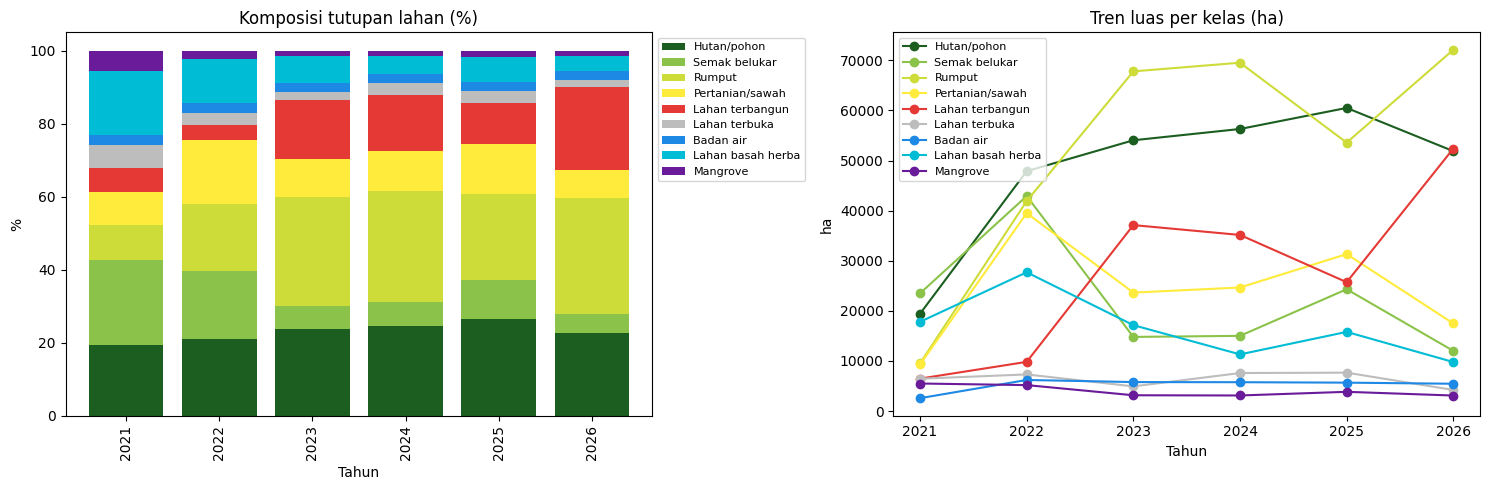

In [10]:
colors = ['#' + c for c in PALETTE]

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
df_pct.plot(kind='bar', stacked=True, ax=ax[0], color=colors, width=0.8)
ax[0].set_title('Komposisi tutupan lahan (%)'); ax[0].set_ylabel('%')
ax[0].legend(bbox_to_anchor=(1.0, 1), fontsize=8)

df_ha.plot(ax=ax[1], marker='o', color=colors)
ax[1].set_title('Tren luas per kelas (ha)'); ax[1].set_ylabel('ha')
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [11]:
# Matriks transisi (ha): BASE_YEAR -> tahun terakhir
def transition(y1, y2):
    t = maps[y1].toInt16().multiply(10).add(maps[y2].toInt16()).rename('t')
    groups = (ee.Image.pixelArea().divide(10000).addBands(t)
              .reduceRegion(reducer=ee.Reducer.sum().group(groupField=1, groupName='trans'),
                            geometry=aoi, scale=30, maxPixels=1e13, tileScale=4)
              .get('groups').getInfo())
    recs = [{'Dari': CLASS_NAMES[int(g['trans']) // 10],
             'Ke': CLASS_NAMES[int(g['trans']) % 10],
             'ha': g['sum']} for g in groups]
    return pd.DataFrame(recs).pivot_table(index='Dari', columns='Ke', values='ha',
                                          aggfunc='sum', fill_value=0).round(1)

Y1, Y2 = BASE_YEAR, YEARS[-1]
trans = transition(Y1, Y2)
print(f'Matriks perubahan {Y1} -> {Y2} (ha)')
display(trans)
trans.to_csv(f'matriks_transisi_{Y1}_{Y2}.csv')

# Perubahan bersih per kelas
net = (df_ha.loc[Y2] - df_ha.loc[Y1]).sort_values()
print(f'Perubahan bersih {Y1} -> {Y2} (ha):')
display(net.round(1))

Matriks perubahan 2022 -> 2026 (ha)


Ke,Badan air,Hutan/pohon,Lahan basah herba,Lahan terbangun,Lahan terbuka,Mangrove,Pertanian/sawah,Rumput,Semak belukar
Dari,,,,,,,,,
Badan air,4990.6,51.6,27.7,209.4,230.1,448.1,113.1,110.1,24.9
Hutan/pohon,42.8,27793.0,251.1,3603.1,38.4,72.3,1173.1,12863.9,2039.7
Lahan basah herba,25.7,1140.7,3991.4,7759.4,341.5,62.1,3547.5,10088.0,741.2
Lahan terbangun,1.1,490.5,39.3,7139.3,225.7,3.0,130.0,1723.4,67.5
Lahan terbuka,136.6,244.5,176.8,2435.4,1819.1,360.3,1156.3,944.7,37.6
Mangrove,177.4,445.4,181.1,539.8,574.8,2006.7,475.3,498.8,283.0
Pertanian/sawah,57.7,2225.3,1318.6,15576.7,767.2,83.4,5806.7,13092.1,572.2
Rumput,2.1,10435.6,566.5,8494.4,50.9,0.5,855.7,20734.7,766.4
Semak belukar,18.3,9044.4,3233.6,6629.3,163.1,64.4,4221.8,12051.0,7481.2


Perubahan bersih 2022 -> 2026 (ha):


,0
Semak belukar,-30893.5
Pertanian/sawah,-22020.6
Lahan basah herba,-17911.4
Lahan terbuka,-3100.5
Mangrove,-2081.3
Badan air,-753.2
Hutan/pohon,3993.6
Rumput,30199.9
Lahan terbangun,42567.0


In [15]:
Map = geemap.Map(center=[-3.0, 114.6], zoom=9)
Map.clear_layers()            # buang lapisan OSM bawaan yang diblokir
Map.add_basemap('HYBRID')     # citra satelit Google + label

Map.centerObject(aoi, 9)
Map.addLayer(comps[YEARS[-1]], {'bands': ['red', 'green', 'blue'], 'min': 0.0, 'max': 0.25},
             f'Citra RGB {YEARS[-1]}', False)
for y in YEARS:
    Map.addLayer(maps[y], {'min': 1, 'max': 9, 'palette': PALETTE},
                 f'Tutupan lahan {y}', y == YEARS[-1])
Map.addLayer(aoi_fc.style(color='000000', fillColor='00000000', width=2), {}, 'Batas kabupaten')
Map.add_legend(title='Tutupan lahan',
               legend_dict={CLASS_NAMES[i + 1]: '#' + PALETTE[i] for i in range(9)})
Map

Map(center=[-3.082323952059086, 114.61914876063757], controls=(WidgetControl(options=['position', 'transparent…

In [13]:
if EXPORT:
    for y in YEARS:
        ee.batch.Export.image.toDrive(
            image=maps[y], description=f'LC_BaritoKuala_{y}', folder='GEE_LandCover',
            region=aoi, scale=30, crs='EPSG:32750', maxPixels=1e13).start()
    print('Task ekspor dimulai — pantau di https://code.earthengine.google.com/tasks')

# Unduh CSV hasil dari Colab:
# from google.colab import files
# files.download('luas_tutupan_lahan_ha.csv')